In [28]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from plots import *
from helper import *
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import OrdinalEncoder, TargetEncoder, OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from category_encoders import CountEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, train_test_split
from sklearn.base import clone
from xgboost import XGBRegressor
import optuna
from funcs import datetime_processing_func, lag_feature_func, region_generation_func

In [29]:
df_prices = pd.read_csv("C:/Users/redli/OneDrive/Desktop/classic ml tasks/regression/Hourly_Gasoline_Prices.csv")
df_fuel_st_info = pd.read_csv(r"C:\Users\redli\OneDrive\Desktop\classic ml tasks\regression\Fuel_Station_Information.csv")

In [30]:
df_full_eda = pd.merge(df_prices, df_fuel_st_info, how = "inner", on = "Id")
df_full_eda = df_full_eda.drop_duplicates()
df_full_eda.head(30)

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
5,12494,1,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766
6,37593,0,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
7,37593,1,1.789,2022-01-02 12:36:25,CARBURANTI PALAZZO S.N.C.,Ies,Stradale,CARBURANTI PALAZZO SNC,BARANELLO,41.516827,14.594655
8,50047,0,1.879,2022-01-02 14:20:37,DI BENEDETTO MARIA AGATA,SP Energia Siciliana,Stradale,stzione di servizio Di Benedetto Maria Agata,VENTIMIGLIA DI SICILIA,37.920051,13.565093
9,52185,0,1.800,2022-01-02 17:25:08,PIRA GIANPAOLO,Q8,Stradale,PIRA GIANPAOLO,BITTI,40.476894,9.382334


In [31]:
from funcs import datetime_processing_func

In [32]:
dt_proc = FunctionTransformer(datetime_processing_func)

In [33]:
df_full_eda.head()

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766


In [34]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from kneed import KneeLocator
from sklearn.impute import SimpleImputer
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
import joblib
from funcs import datetime_processing_func, train_test_splitting

bundle = joblib.load("hptunned.joblib")

In [35]:
pipe = bundle["pipeline"]
hptunned_model = bundle["xgboost"]
hptunned_metrics = bundle["metrics"]

In [10]:
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('dt_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out v

In [11]:
X_train, X_test, y_train, y_test = train_test_splitting(df_full_eda)

def cross_va(pipe, X_train, X_test, y_train, y_test):
    
    temp_pipe = clone(pipe)
    cv = TimeSeriesSplit(n_splits=5)
    
    folds = []
    
    for num, (tr, vl) in enumerate(cv.split(X_train, y_train)):
        X_tr = temp_pipe.fit_transform(X_train.iloc[tr], y_train.iloc[tr])
        X_vl = temp_pipe.transform(X_train.iloc[vl])
        folds.append([X_tr, y_train.iloc[tr], X_vl, y_train.iloc[vl]])
    return folds
    
def metrics_calculate(folds):
    
    temp_result_metrics = {"R2" : [], "MAPE" : [], "RMSE" : []}
    
    for fold in folds:
        temp_model = clone(hptunned_model)
        temp_model.fit(fold[0], fold[1])
        y_pred = temp_model.predict(fold[2])
         
        temp_result_metrics["R2"].append(r2_score(fold[3], y_pred)), 
        temp_result_metrics["MAPE"].append(mean_absolute_percentage_error(fold[3], y_pred)), 
        temp_result_metrics["RMSE"].append(root_mean_squared_error(fold[3], y_pred))
    
    temp_result_metrics["R2"] = np.mean(temp_result_metrics["R2"])
    temp_result_metrics["MAPE"] = np.mean(temp_result_metrics["MAPE"])
    temp_result_metrics["RMSE"] = np.mean(temp_result_metrics["RMSE"])
    
    diff_metrics = {k: temp_result_metrics[k] - hptunned_metrics[k] for k in temp_result_metrics}
    sns.heatmap(pd.Series(diff_metrics).to_frame(), annot= True, cmap = 'coolwarm')

    return temp_result_metrics

# Feature engineering

## Лаг признак цен

Первое что приходит в голову, конечно как то сохранять историю цен и передавать ее в признак (Идея моя, но то как примерно реализовать спрашивал у клода). В первую очередь попытаюсь доавбить лаг признак, вытащу таргет, смещу на одну позицию в перед, так что для каждого ценника будет сущетсвовать ценник, записанный в предыдущий раз, этой же компании

In [12]:
df_full_eda = df_full_eda.sort_values("Date")

df_w_price_lag = df_full_eda.copy()

df_w_price_lag = df_w_price_lag.drop_duplicates().sort_values(["Id", "isSelf", "Date"])

df_w_price_lag["price_lag"] = df_full_eda.groupby(["Id", "isSelf"])["Price"].shift(1)

df_w_price_lag

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine,price_lag
37619,3464,0,2.269,2022-01-06 21:30:09,STAZ.SERV.PO EST ANDREOTTI CLAUDIO DI ANDREOTT...,Api-Ip,Autostradale,PO EST,FERRARA,44.880119,11.570833,NaN
105322,3464,0,2.104,2022-02-05 22:00:06,STAZ.SERV.PO EST ANDREOTTI CLAUDIO DI ANDREOTT...,Api-Ip,Autostradale,PO EST,FERRARA,44.880119,11.570833,2.269
126960,3464,0,2.104,2022-02-11 13:00:10,STAZ.SERV.PO EST ANDREOTTI CLAUDIO DI ANDREOTT...,Api-Ip,Autostradale,PO EST,FERRARA,44.880119,11.570833,2.104
143888,3464,0,2.127,2022-02-12 21:00:07,STAZ.SERV.PO EST ANDREOTTI CLAUDIO DI ANDREOTT...,Api-Ip,Autostradale,PO EST,FERRARA,44.880119,11.570833,2.104
147613,3464,0,2.034,2022-03-04 14:00:05,STAZ.SERV.PO EST ANDREOTTI CLAUDIO DI ANDREOTT...,Api-Ip,Autostradale,PO EST,FERRARA,44.880119,11.570833,2.127
...,...,...,...,...,...,...,...,...,...,...,...,...
1976238,54169,1,1.689,2022-11-21 15:13:01,TAMOIL,Tamoil,Stradale,TAMOIL,LATINA,41.457970,12.862230,1.699
2136687,54169,1,1.729,2022-12-07 16:38:19,TAMOIL,Tamoil,Stradale,TAMOIL,LATINA,41.457970,12.862230,1.689
1188498,54174,0,2.079,2022-06-29 16:19:13,TIBER,Q8,Stradale,TIBER,NAPOLI,40.888994,14.256987,NaN
1412022,54174,0,1.790,2022-09-09 15:56:56,TIBER,Q8,Stradale,TIBER,NAPOLI,40.888994,14.256987,2.079


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001938 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1853
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 10
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003769 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1871
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 10
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005761 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not eno

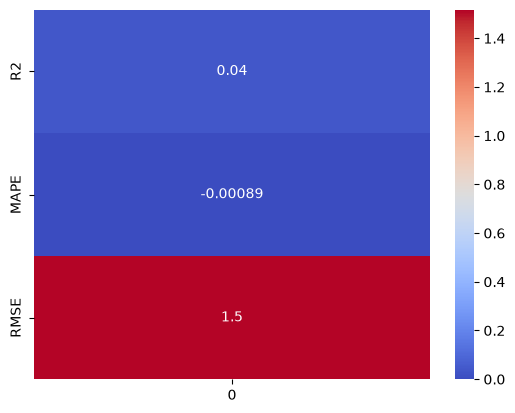

In [13]:
target_mean = df_full_eda["Price"].mean()

folds = cross_va(pipe,X_train, X_test, y_train, y_test)

result_metrics_1 = metrics_calculate(folds)

Как видно из графика на пол сотой доли вырос R2, что определенно плюс, значит у модели появился признак, который лучше описывает тенденция в данных

## Признак - Регион

Так же одно из немногих потенциальных способов увелечения итогового скора это создание признака "Область"(Тоже самое, что и с предыдущим, решение мое, изначально хотел делать с dbscan, но потом решил, что будет черезчур, так что решил заменить на обычный kmeans), в датасете присутствуют значения Ширины и Долготы, при помощи dbscan или kmean, как в моем случае, можно будет выделить класстеры, для которых модель может выделить завимость

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001917 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1861
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 11
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.015733 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1881
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 11
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005916 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total 

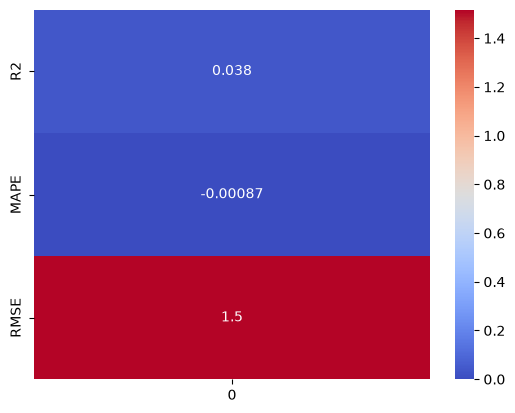

In [14]:
target_mean = df_full_eda["Price"].mean()
result_metrics = {}

fill_na_coords = SimpleImputer(strategy = "mean").fit_transform(df_full_eda[["Latitude", "Longitudine"]])

region_generation_model = KMeans(n_clusters = 10)

folds = cross_va(pipe,X_train, X_test, y_train, y_test)

for fold in folds:
    fold[0]["region"] = region_generation_model.fit_predict(fold[0])
    fold[2]["region"] = region_generation_model.predict(fold[2])

result_metrics_2 = metrics_calculate(folds)

Незначительно вырос показатель R2, а так же RMSE

## Убираю энкодеры

In [15]:
if "manager_ecoder" == pipe["transformer"].transformers[2][0]:
    pipe["transformer"].transformers[2] = ("manager_encoder", pipe["transformer"].transformers[2][1], pipe["transformer"].transformers[2][2])

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002061 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1853
[LightGBM] [Info] Number of data points in the train set: 319284, number of used features: 10
[LightGBM] [Info] Start training from score 1.834126
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003539 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1869
[LightGBM] [Info] Number of data points in the train set: 638564, number of used features: 10
[LightGBM] [Info] Start training from score 1.825438
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.005673 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not eno

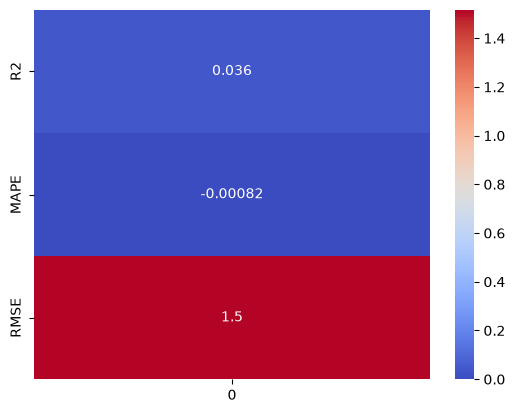

In [16]:
alt_pipe = clone(pipe)
alt_pipe.set_params(
        transformer__city_encoder='drop',
        transformer__manager_encoder='drop',
        transformer__company_encoder='drop'
    )
X_train, X_test, y_train, y_test = train_test_splitting(df_full_eda)

folds = cross_va(pipe, X_train, X_test, y_train, y_test) 

result_metrics_3 = metrics_calculate(folds)

Значения упали, что ожидаемо, идея если честно так себе, в итоге получилось падение по всем метрикам

In [17]:
df_full_eda.head()

,Id,isSelf,Price,Date,Fuel_station_manager,Petrol_company,Type,Station_name,City,Latitude,Longitudine
0,51169,1,1.943,2022-01-01 11:45:53,AURA PETROLSERVICE S.N.C. DI LANZA BRUNO & C.,Api-Ip,Autostradale,BAUDUCCHI OVEST,MONCALIERI,44.977978,7.700216
1,44566,1,1.725,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
2,44566,0,1.775,2022-01-02 11:15:08,BOVE SOCIETA' A RESPONSABILITA' LIMITATA SEMPL...,Esso,Stradale,EASY,GALLIPOLI,40.059118,18.032323
3,20026,1,1.729,2022-01-02 11:27:01,FIARDI TRADING - SOCIETA' A RESPONSABILITA' LI...,Api-Ip,Stradale,IP,CAMPOMARINO,41.938508,15.076976
4,12494,0,1.559,2022-01-02 12:07:25,BUSSINELLO S.R.L.,Pompe Bianche,Stradale,Impianto Verona Petroli - San Bonifacio,SAN BONIFACIO,45.386059,11.273766


In [18]:
from funcs import Region_Generator

In [19]:
lag_feature_transformer = FunctionTransformer(lag_feature_func, kw_args={"sort_feature" : ["Date"]})
region_generation = Region_Generator(n_clusters=10, random_state=42)

In [23]:
final_pipe = list(clone(pipe).steps)
final_pipe.insert(3, ("regions", region_generation))
final_pipe.insert(5, ("dropper", ColumnTransformer([("drop_cols", "drop", ["Id"])], remainder='passthrough')))
final_pipe = Pipeline(final_pipe[:-2])
final_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('fill_na_knn', ...), ('dt_proc', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('fill_na_city', ...), ('fill_na_cords', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out v

In [24]:
df_features = df_full_eda.drop_duplicates().copy()
df_features = lag_feature_func(df_features, sort_feature="Date")

X_train, X_test, y_train, y_test = train_test_splitting(df_features)

temp_pipe = clone(final_pipe)
X_train_proc = temp_pipe.fit_transform(X_train, y_train)
X_test_proc = temp_pipe.transform(X_test)

model = clone(hptunned_model)
model.fit(X_train_proc, y_train)
y_pred = model.predict(X_test_proc)

result_metrics = {
    "R²": r2_score(y_test, y_pred),
    "MAE": mean_absolute_error(y_test, y_pred),
    "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100,
    "RMSE": root_mean_squared_error(y_test, y_pred),
}

print(pd.Series(result_metrics))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.018838 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1988
[LightGBM] [Info] Number of data points in the train set: 1915684, number of used features: 11
[LightGBM] [Info] Start training from score 1.865682
R²         0.750579
MAE        0.046117
MAPE, %    2.649804
RMSE       0.067459
dtype: float64


<Axes: >

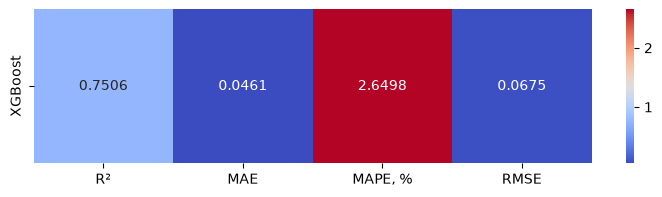

In [25]:
metrics_df = pd.DataFrame([result_metrics], index=["XGBoost"])

plt.figure(figsize=(9, 2))
sns.heatmap(metrics_df, annot=True, fmt=".4f", cmap="coolwarm")

In [26]:
result_metrics

{'R²': 0.7505787426705167,
 'MAE': 0.04611740091975282,
 'MAPE, %': 2.6498041634871425,
 'RMSE': 0.06745883319694096}

In [27]:
results = {
    "pipeline" : final_pipe,
    "model" : hptunned_model,
    "metrics" : result_metrics
}

In [ ]:
joblib.dump(results, "final_result.joblib")